# WPTG 2026-2027 – Wybrane Problemy Teorii Grafów
### Projekt: System transformacji grafowych (Graph Grammars)
**Prowadzący:** dr hab. Adam Sędziwy, prof. AGH

Notatnik demonstruje działanie modularnego pakietu `wptg` na oficjalnych danych testowych ze specyfikacji:
- **Graf testowy:** `graf_voronoi_ABCDE.json` – gęsty graf planarny z diagramu Voronoia (20 wierzchołków, 50 krawędzi, rzeczywiste współrzędne 2D)
- **Gramatyka testowa:** `gramatyka_ABCDE.json` – zaawansowana gramatyka siatek trójkątnych z podziałem węzłów (15 produkcji, rozbudowane reguły osadzania)
- Prezentacja strategii selekcji 1 (`ALL_ASCENDING`) oraz 2 (`FIRST_LOWEST`)
- Prezentacja obsługi wiszących krawędzi 1 (`CANCEL`) oraz 2 (`DELETE`)
- Wizualizacje 2D oraz reprezentacja tabelaryczna (HTML i ASCII) połączeń, macierzy sąsiedztwa i krawędzi


In [1]:
import json
from wptg import (
    Graph,
    Vertex,
    Edge,
    Production,
    Grammar,
    DanglingEdges,
    SelectionStrategy,
    DanglingEdgesHandling,
    TransformationSystem,
    GraphTableFormatter,
)


## 1. Wczytanie i wizualizacja grafu testowego: Diagram Voronoia (`graf_voronoi_ABCDE.json`)
Wczytanie pełnego grafu testowego podanego w specyfikacji zadania. Graf posiada 20 wierzchołków z etykietami od A do E, 50 krawędzi z wagami oraz rzeczywiste współrzędne w przestrzeni 2D.


In [2]:
with open("graf_voronoi_ABCDE.json", "r", encoding="utf-8") as f:
    voronoi_data = json.load(f)

g_voronoi = Graph.from_dict(voronoi_data)

print(f"Nazwa grafu: {g_voronoi.name}")
print(f"Skierowany: {g_voronoi.directed}")
print(f"Liczba wierzchołków: {len(g_voronoi.vertices)}")
print(f"Liczba krawędzi: {len(g_voronoi.edges)}")


Nazwa grafu: Graf G z diagramu Voronoia (20 wierzchołków, etykiety A–E)
Skierowany: False
Liczba wierzchołków: 20
Liczba krawędzi: 50


### Wizualizacja grafu Voronoia w przestrzeni 2D
Pakiet `wptg` automatycznie wykorzystuje współrzędne `(x, y)` wierzchołków do odtworzenia geometrii diagramu Voronoia.


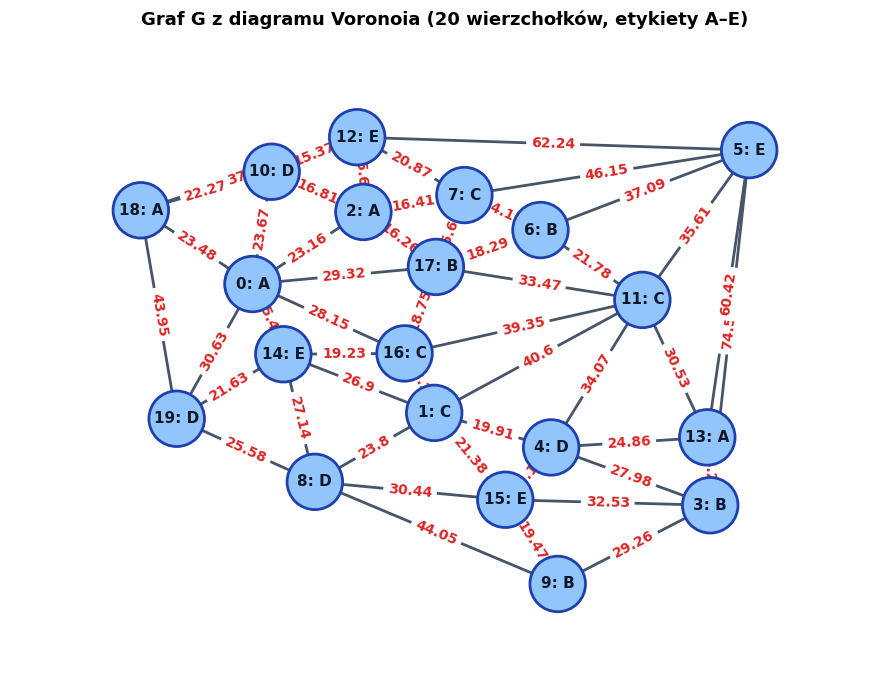

In [3]:
g_voronoi.visualize(figsize=(9, 7))


### Reprezentacja tabelkowa grafu Voronoia
Poniżej przedstawiono tabelę połączeń (stopnie węzłów, etykiety i wagi incydentnych krawędzi) w stylizowanym formacie HTML.


In [4]:
g_voronoi.display_table(mode="connections")


Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,7,"2 (A) [waga: 23.16], 10 (D) [waga: 23.67], 14 (E) [waga: 15.47], 16 (C) [waga: 28.15], 17 (B) [waga: 29.32], 18 (A) [waga: 23.48], 19 (D) [waga: 30.63]"
1,C,6,"4 (D) [waga: 19.91], 8 (D) [waga: 23.8], 11 (C) [waga: 40.6], 14 (E) [waga: 26.9], 15 (E) [waga: 21.38], 16 (C) [waga: 13.29]"
2,A,5,"0 (A) [waga: 23.16], 7 (C) [waga: 16.41], 10 (D) [waga: 16.81], 12 (E) [waga: 15.66], 17 (B) [waga: 16.26]"
3,B,5,"4 (D) [waga: 27.98], 5 (E) [waga: 74.51], 9 (B) [waga: 29.26], 13 (A) [waga: 14.21], 15 (E) [waga: 32.53]"
4,D,5,"1 (C) [waga: 19.91], 3 (B) [waga: 27.98], 11 (C) [waga: 34.07], 13 (A) [waga: 24.86], 15 (E) [waga: 13.14]"
5,E,6,"3 (B) [waga: 74.51], 6 (B) [waga: 37.09], 7 (C) [waga: 46.15], 11 (C) [waga: 35.61], 12 (E) [waga: 62.24], 13 (A) [waga: 60.42]"
6,B,4,"5 (E) [waga: 37.09], 7 (C) [waga: 14.12], 11 (C) [waga: 21.78], 17 (B) [waga: 18.29]"
7,C,5,"2 (A) [waga: 16.41], 5 (E) [waga: 46.15], 6 (B) [waga: 14.12], 12 (E) [waga: 20.87], 17 (B) [waga: 15.69]"
8,D,5,"1 (C) [waga: 23.8], 9 (B) [waga: 44.05], 14 (E) [waga: 27.14], 15 (E) [waga: 30.44], 19 (D) [waga: 25.58]"
9,B,3,"3 (B) [waga: 29.26], 8 (D) [waga: 44.05], 15 (E) [waga: 19.47]"


## 2. Wczytanie oficjalnej gramatyki siatek trójkątnych (`gramatyka_ABCDE.json`)
Gramatyka służy do generowania i zagęszczania siatek trójkątnych. Zawiera 15 produkcji implementujących m.in. doklejanie nowych trójkątów, podział węzła z dziedziczeniem sąsiadów oraz terminację.


In [5]:
with open("gramatyka_ABCDE.json", "r", encoding="utf-8") as f:
    grammar_data = json.load(f)

gram = Grammar.from_dict(grammar_data)

print(f"Nazwa gramatyki: {gram.name}")
print(f"Nieterminale: {gram.nonterminals}")
print(f"Terminale: {gram.terminals}")
print(f"Domyślna obsługa krawędzi wiszących: {gram.dangling_edges.value}")
print(f"Liczba produkcji: {len(gram.productions)}")


Nazwa gramatyki: Gramatyka grafowa ABCDE (siatki trójkątne z podziałem węzłów)
Nieterminale: ['A', 'B', 'C', 'D', 'E']
Terminale: ['a', 'b', 'c', 'd', 'e']
Domyślna obsługa krawędzi wiszących: forbid
Liczba produkcji: 15


### Zestawienie produkcji gramatyki ABCDE


In [6]:
for p in gram.productions:
    l_v = len(p.left.vertices)
    r_v = len(p.right.vertices)
    mappings = len(p.mapping)
    embeddings = len(p.embedding)
    print(f"[{p.name.ljust(3)}] {p.description}")
    print(f"      LHS wierzchołki: {l_v}, RHS wierzchołki: {r_v}, mapping: {mappings}, embeddingi: {embeddings}")


[P1 ] A → trójkąt A–D–E (doklejenie nowego trójkąta w węźle A; A zachowuje swoich sąsiadów)
      LHS wierzchołki: 1, RHS wierzchołki: 3, mapping: 1, embeddingi: 0
[P2 ] B → b – E (B staje się terminalem b; nowy węzeł E tworzy trójkąty z sąsiadami o etykiecie A)
      LHS wierzchołki: 1, RHS wierzchołki: 2, mapping: 1, embeddingi: 1
[P3 ] C → c – D (C staje się terminalem c; nowy węzeł D łączy się z sąsiadami o etykietach B oraz b)
      LHS wierzchołki: 1, RHS wierzchołki: 2, mapping: 1, embeddingi: 2
[P4 ] D → d – A (D staje się terminalem d; nowy węzeł A łączy się z sąsiadami o etykietach E i C)
      LHS wierzchołki: 1, RHS wierzchołki: 2, mapping: 1, embeddingi: 2
[P5 ] E → e – B (E staje się terminalem e; nowy węzeł B łączy się z sąsiadami o etykiecie D)
      LHS wierzchołki: 1, RHS wierzchołki: 2, mapping: 1, embeddingi: 1
[P6 ] A → B – C (podział węzła: obaj następcy dziedziczą wszystkich sąsiadów A)
      LHS wierzchołki: 1, RHS wierzchołki: 2, mapping: 0, embeddingi: 1
[P7 ]

### Wizualizacja wybranych nietrywialnych produkcji
Wizualizacja dwudzielna przedstawia lewą stronę (wzorzec) oraz prawą stronę (podstawienie).
Węzły zielone są zachowywane (`mapping`), czerwone są usuwane, a pomarańczowe nowo tworzone.


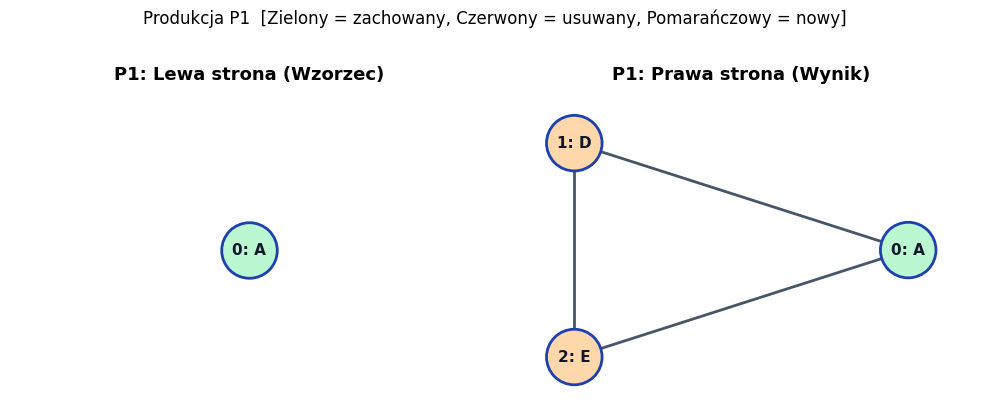

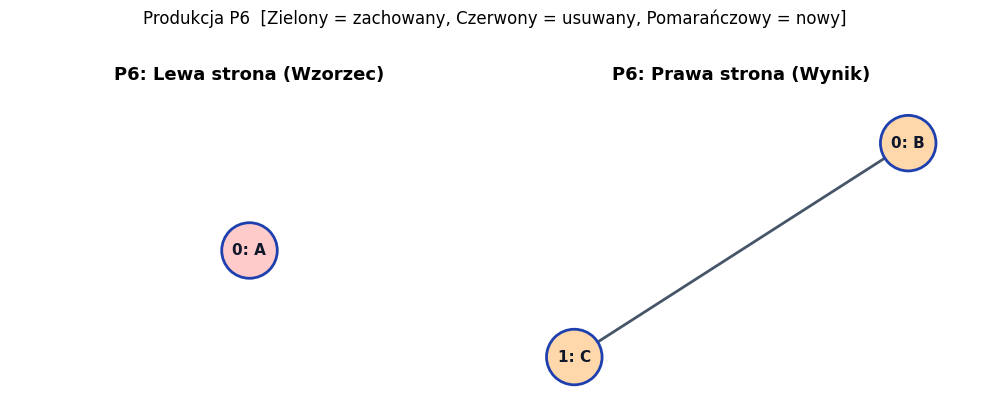

In [7]:
p1 = gram.get_production("P1")
p1.visualize(figsize=(10, 4))

p6 = gram.get_production("P6")
p6.visualize(figsize=(10, 4))


## 3. Wyprowadzenie siatki trójkątnej ze startowego grafu gramatyki
Rozpoczynamy od grafu startowego gramatyki (trójkąt A - B - C) i stosujemy sekwencję produkcji:
1. `P1`: doklejenie trójkąta w węźle A ($A \rightarrow A - D - E$)
2. `P6`: podział węzła A ($A \rightarrow B - C$ z regułą osadzenia rozszerzającą krawędzie do obu węzłów)
3. `P5`: doklejenie w węźle E ($E \rightarrow e - B$ z połączeniem nowego B z sąsiadem D)
4. `P11`, `P12`, `P13`, `P14`, `P15` (Strategia 1): terminacja wszystkich pozostałych nieterminali w małe litery terminalne


In [8]:
ts_mesh = TransformationSystem(G=gram.start_graph.copy(), T=gram)

ts_mesh.apply(["P1", "P6", "P5"], selection_strategy=2, dangling_edges_handling=1)
ts_mesh.apply(["P11", "P12", "P13", "P14", "P15"], selection_strategy=1, dangling_edges_handling=1)

for i, (prod, g_step) in enumerate(ts_mesh.History):
    v_str = ", ".join(f"{v.index}:{v.label}" for v in g_step.vertices)
    print(f"Krok {i+1} [{prod.name}]: wierzchołki=[{v_str}], liczba krawędzi={len(g_step.edges)}")


Krok 1 [P1]: wierzchołki=[0:A, 1:B, 2:C, 3:D, 4:E], liczba krawędzi=6
Krok 2 [P6]: wierzchołki=[1:B, 2:C, 3:D, 4:E, 5:B, 6:C], liczba krawędzi=11
Krok 3 [P5]: wierzchołki=[1:B, 2:C, 3:D, 4:e, 5:B, 6:C, 7:B], liczba krawędzi=13
Krok 4 [P12]: wierzchołki=[1:b, 2:C, 3:D, 4:e, 5:B, 6:C, 7:B], liczba krawędzi=13
Krok 5 [P12]: wierzchołki=[1:b, 2:C, 3:D, 4:e, 5:b, 6:C, 7:B], liczba krawędzi=13
Krok 6 [P12]: wierzchołki=[1:b, 2:C, 3:D, 4:e, 5:b, 6:C, 7:b], liczba krawędzi=13
Krok 7 [P13]: wierzchołki=[1:b, 2:c, 3:D, 4:e, 5:b, 6:C, 7:b], liczba krawędzi=13
Krok 8 [P13]: wierzchołki=[1:b, 2:c, 3:D, 4:e, 5:b, 6:c, 7:b], liczba krawędzi=13
Krok 9 [P14]: wierzchołki=[1:b, 2:c, 3:d, 4:e, 5:b, 6:c, 7:b], liczba krawędzi=13


### Wizualizacja ewolucji siatki w kolejnych krokach wyprowadzenia


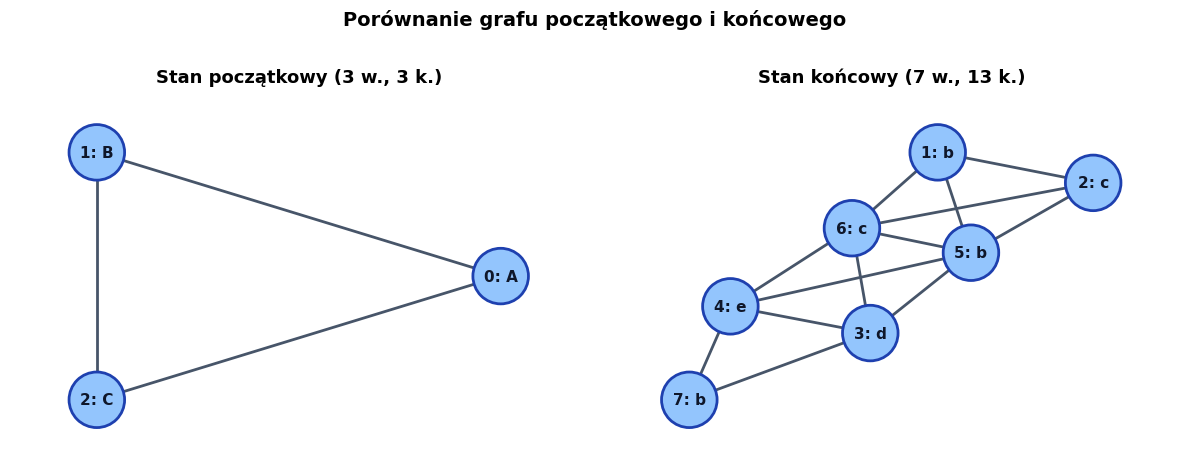

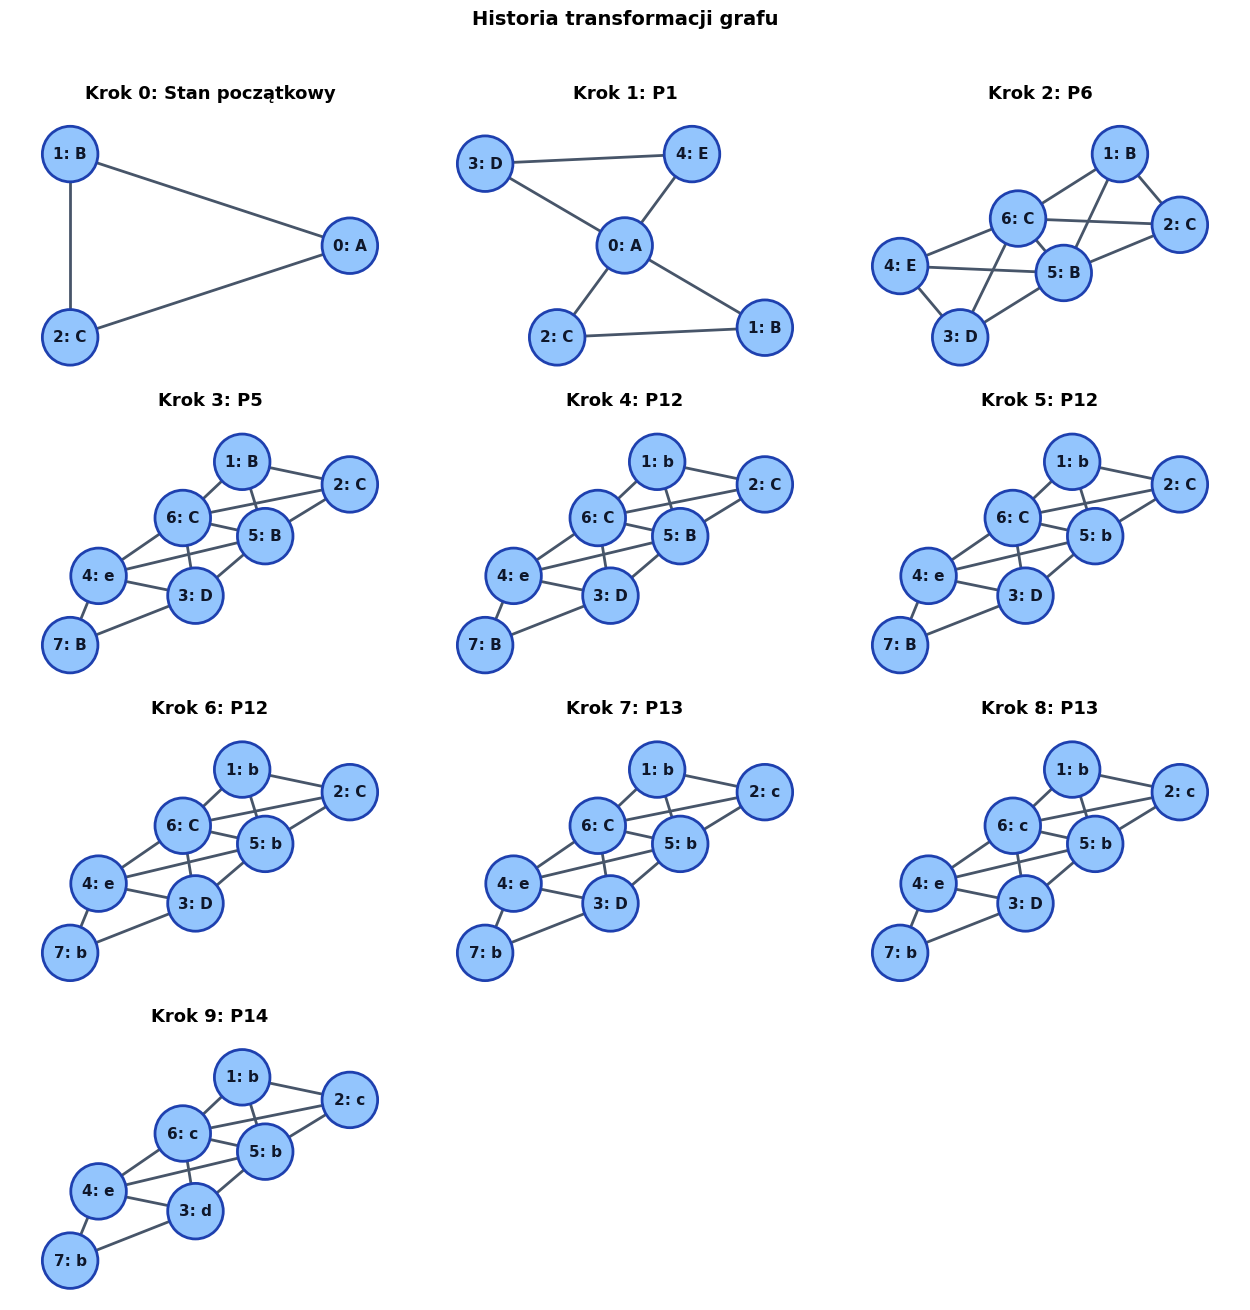

In [9]:
ts_mesh.visualize_initial_and_final(figsize=(12, 4.5))
ts_mesh.visualize_history(figsize_per_step=(4.2, 3.2), include_initial=True)


### Tabele połączeń dla kolejnych kroków wyprowadzenia siatki


In [10]:
ts_mesh.display_history_tables(mode="connections")


Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,4,"1 (B), 2 (C), 3 (D), 4 (E)"
1,B,2,"0 (A), 2 (C)"
2,C,2,"1 (B), 0 (A)"
3,D,2,"0 (A), 4 (E)"
4,E,2,"3 (D), 0 (A)"
Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
1,B,3,"2 (C), 5 (B), 6 (C)"
2,C,3,"1 (B), 5 (B), 6 (C)"
3,D,3,"4 (E), 5 (B), 6 (C)"
4,E,3,"3 (D), 5 (B), 6 (C)"


## 4. Nietrywialne transformacje na pełnym grafie Voronoia
Demonstracja obu wymaganych strategii selekcji na rzeczywistym grafie Voronoia o 20 wierzchołkach i 50 krawędziach.

### Strategia 2 (`FIRST_LOWEST`): Wybór pasującego węzła o najniższym indeksie
Aplikujemy produkcję `P6` ($A \rightarrow B - C$), która usuwa wierzchołek A i zastępuje go parą B i C połączoną nową krawędzią.
Węzeł 0 (A) ma stopień 7 w grafie Voronoia. Zgodnie z regułą osadzania `neighborLabel: "*", connectTo: [0, 1]`, wszystkie 7 krawędzi zostaje zduplikowanych do obu nowych wierzchołków.


Początkowa liczba wierzchołków: 20
Początkowa liczba krawędzi: 50
Zastosowano kroków: 1
Liczba wierzchołków po P6: 21
Liczba krawędzi po P6: 58


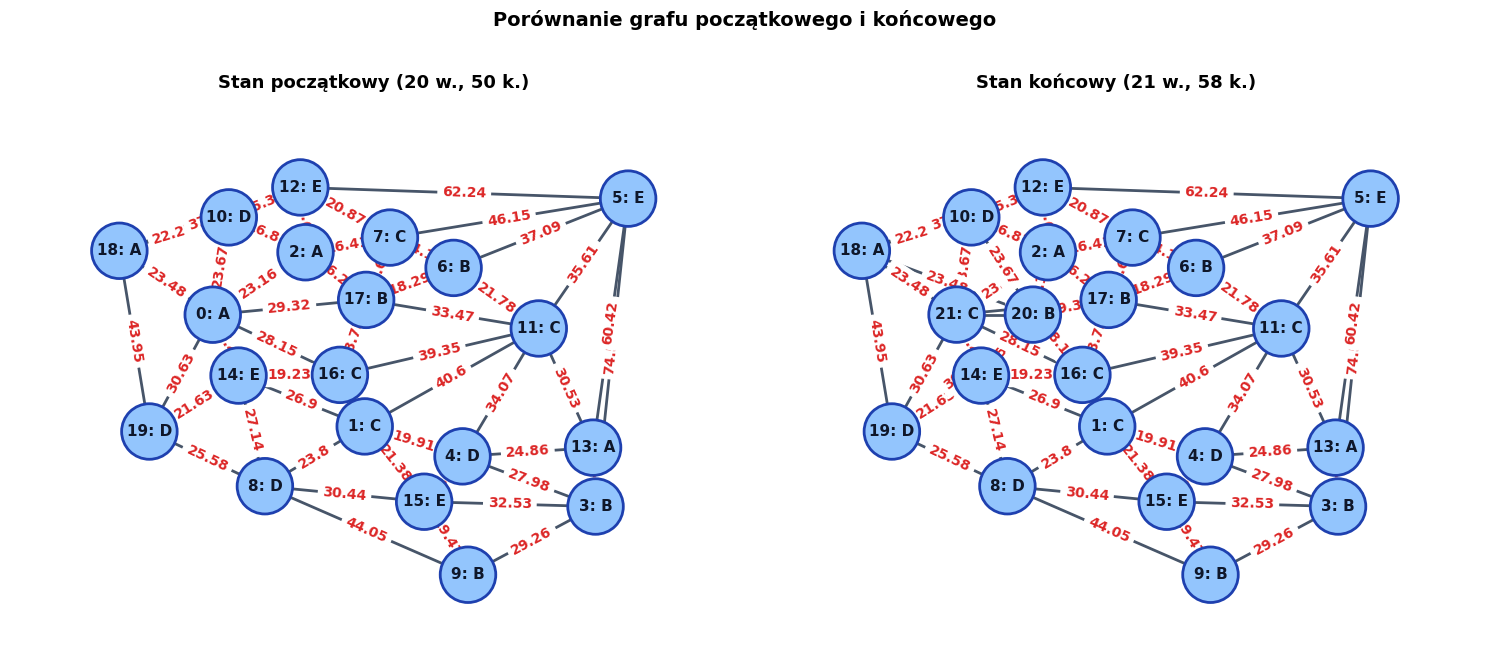

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
1,C,6,"4 (D) [waga: 19.91], 8 (D) [waga: 23.8], 11 (C) [waga: 40.6], 14 (E) [waga: 26.9], 15 (E) [waga: 21.38], 16 (C) [waga: 13.29]"
2,A,6,"7 (C) [waga: 16.41], 10 (D) [waga: 16.81], 12 (E) [waga: 15.66], 17 (B) [waga: 16.26], 20 (B) [waga: 23.16], 21 (C) [waga: 23.16]"
3,B,5,"4 (D) [waga: 27.98], 5 (E) [waga: 74.51], 9 (B) [waga: 29.26], 13 (A) [waga: 14.21], 15 (E) [waga: 32.53]"
4,D,5,"1 (C) [waga: 19.91], 3 (B) [waga: 27.98], 11 (C) [waga: 34.07], 13 (A) [waga: 24.86], 15 (E) [waga: 13.14]"
5,E,6,"3 (B) [waga: 74.51], 6 (B) [waga: 37.09], 7 (C) [waga: 46.15], 11 (C) [waga: 35.61], 12 (E) [waga: 62.24], 13 (A) [waga: 60.42]"
6,B,4,"5 (E) [waga: 37.09], 7 (C) [waga: 14.12], 11 (C) [waga: 21.78], 17 (B) [waga: 18.29]"
7,C,5,"2 (A) [waga: 16.41], 5 (E) [waga: 46.15], 6 (B) [waga: 14.12], 12 (E) [waga: 20.87], 17 (B) [waga: 15.69]"
8,D,5,"1 (C) [waga: 23.8], 9 (B) [waga: 44.05], 14 (E) [waga: 27.14], 15 (E) [waga: 30.44], 19 (D) [waga: 25.58]"
9,B,3,"3 (B) [waga: 29.26], 8 (D) [waga: 44.05], 15 (E) [waga: 19.47]"
10,D,5,"2 (A) [waga: 16.81], 12 (E) [waga: 15.37], 18 (A) [waga: 22.27], 20 (B) [waga: 23.67], 21 (C) [waga: 23.67]"


In [11]:
ts_voronoi_s2 = TransformationSystem(G=g_voronoi.copy(), T=gram)

print(f"Początkowa liczba wierzchołków: {len(ts_voronoi_s2.G.vertices)}")
print(f"Początkowa liczba krawędzi: {len(ts_voronoi_s2.G.edges)}")

applied_p6 = ts_voronoi_s2.apply(["P6"], selection_strategy=2, dangling_edges_handling=1)

print(f"Zastosowano kroków: {len(applied_p6)}")
print(f"Liczba wierzchołków po P6: {len(ts_voronoi_s2.G.vertices)}")
print(f"Liczba krawędzi po P6: {len(ts_voronoi_s2.G.edges)}")

ts_voronoi_s2.visualize_initial_and_final(figsize=(15, 6.5))
ts_voronoi_s2.G.display_table(mode="connections")


### Strategia 1 (`ALL_ASCENDING`): Zastosowanie do wszystkich pasujących węzłów rosnąco
Stosujemy produkcję terminującą `P11` ($A \rightarrow a$) ze strategią 1.
Wszystkie wierzchołki o etykiecie A w całym grafie Voronoia zostają w jednym kroku przekształcone w terminale a w kolejności rosnących indeksów.


In [12]:
ts_voronoi_s1 = TransformationSystem(G=ts_voronoi_s2.G.copy(), T=gram)

applied_p11 = ts_voronoi_s1.apply(["P11"], selection_strategy=1, dangling_edges_handling=1)

print(f"Liczba wykonanych przekształceń w kroku P11: {len(applied_p11)}")
for prod, g_step in applied_p11:
    v_a = [v.index for v in g_step.vertices if v.label == "a"]
    print(f"Zastosowano {prod.name}, zaktualizowane terminale 'a': {v_a}")

ts_voronoi_s1.G.display_table(mode="connections")


Liczba wykonanych przekształceń w kroku P11: 3
Zastosowano P11, zaktualizowane terminale 'a': [2]
Zastosowano P11, zaktualizowane terminale 'a': [2, 13]
Zastosowano P11, zaktualizowane terminale 'a': [2, 13, 18]


Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
1,C,6,"4 (D) [waga: 19.91], 8 (D) [waga: 23.8], 11 (C) [waga: 40.6], 14 (E) [waga: 26.9], 15 (E) [waga: 21.38], 16 (C) [waga: 13.29]"
2,a,6,"7 (C) [waga: 16.41], 10 (D) [waga: 16.81], 12 (E) [waga: 15.66], 17 (B) [waga: 16.26], 20 (B) [waga: 23.16], 21 (C) [waga: 23.16]"
3,B,5,"4 (D) [waga: 27.98], 5 (E) [waga: 74.51], 9 (B) [waga: 29.26], 13 (a) [waga: 14.21], 15 (E) [waga: 32.53]"
4,D,5,"1 (C) [waga: 19.91], 3 (B) [waga: 27.98], 11 (C) [waga: 34.07], 13 (a) [waga: 24.86], 15 (E) [waga: 13.14]"
5,E,6,"3 (B) [waga: 74.51], 6 (B) [waga: 37.09], 7 (C) [waga: 46.15], 11 (C) [waga: 35.61], 12 (E) [waga: 62.24], 13 (a) [waga: 60.42]"
6,B,4,"5 (E) [waga: 37.09], 7 (C) [waga: 14.12], 11 (C) [waga: 21.78], 17 (B) [waga: 18.29]"
7,C,5,"2 (a) [waga: 16.41], 5 (E) [waga: 46.15], 6 (B) [waga: 14.12], 12 (E) [waga: 20.87], 17 (B) [waga: 15.69]"
8,D,5,"1 (C) [waga: 23.8], 9 (B) [waga: 44.05], 14 (E) [waga: 27.14], 15 (E) [waga: 30.44], 19 (D) [waga: 25.58]"
9,B,3,"3 (B) [waga: 29.26], 8 (D) [waga: 44.05], 15 (E) [waga: 19.47]"
10,D,5,"2 (a) [waga: 16.81], 12 (E) [waga: 15.37], 18 (a) [waga: 22.27], 20 (B) [waga: 23.67], 21 (C) [waga: 23.67]"


## 5. Obsługa wiszących krawędzi: Anulowanie (`CANCEL` = 1) vs Usunięcie (`DELETE` = 2)
W tej sekcji sprawdzamy zachowanie systemu, gdy usuwany jest wierzchołek posiadający krawędzie do reszty grafu, dla których nie zdefiniowano reguły osadzenia (embedding).
Definiujemy produkcję `P_delete_C`, która usuwa węzeł C bez reguł embeddingu, i testujemy ją na węźle 1 w grafie Voronoia (węzeł 1 to C posiadający wielu sąsiadów).


In [13]:
P_delete_C = Production(
    name="P_delete_C_no_embedding",
    left=Graph(vertices=[Vertex(0, "C")]),
    right=Graph(vertices=[Vertex(0, "c_isolated")]),
    mapping=[],
    embedding=[]
)

print(f"Węzeł 1 w grafie Voronoia: {g_voronoi.get_vertex(1)}")
incident_to_1 = [e for e in g_voronoi.edges if e.u == 1 or e.v == 1]
print(f"Liczba krawędzi incydentnych z węzłem 1: {len(incident_to_1)}")

ts_cancel = TransformationSystem(G=g_voronoi.copy(), T=gram)
res_cancel = ts_cancel.apply([P_delete_C], selection_strategy=2, dangling_edges_handling=1)
print(f"Tryb 1 (CANCEL): liczba wykonanych transformacji = {len(res_cancel)} (brak modyfikacji grafu)")

ts_delete = TransformationSystem(G=g_voronoi.copy(), T=gram)
res_delete = ts_delete.apply([P_delete_C], selection_strategy=2, dangling_edges_handling=2)
print(f"Tryb 2 (DELETE): liczba wykonanych transformacji = {len(res_delete)}")
print(f"Węzeł 1 obecny po DELETE: {ts_delete.G.get_vertex(1) is not None}")
print(f"Liczba krawędzi przed: {len(g_voronoi.edges)}, po DELETE: {len(ts_delete.G.edges)}")


Węzeł 1 w grafie Voronoia: Vertex(index=1, label='C', x=46.727, y=37.05)
Liczba krawędzi incydentnych z węzłem 1: 6
Tryb 1 (CANCEL): liczba wykonanych transformacji = 0 (brak modyfikacji grafu)
Tryb 2 (DELETE): liczba wykonanych transformacji = 1
Węzeł 1 obecny po DELETE: False
Liczba krawędzi przed: 50, po DELETE: 44


## 6. Zestawienie reprezentacji tabelarycznych grafu
Pakiet `wptg` udostępnia reprezentacje w postaci:
- Tabeli połączeń (stopnie wierzchołków, etykiety i wagi)
- Macierzy sąsiedztwa
- Listy krawędzi
Zarówno w wersji HTML (dla Jupyter Notebook) jak i w czystej wersji tekstowej ASCII (do logów i konsoli).


In [14]:
small_sample_graph = ts_mesh.G

print("=== Reprezentacja tekstowa ASCII: Tabela połączeń ===")
small_sample_graph.print_table(mode="connections")

print("=== Reprezentacja tekstowa ASCII: Macierz sąsiedztwa ===")
small_sample_graph.print_table(mode="matrix")

print("=== Reprezentacja tekstowa ASCII: Lista krawędzi ===")
small_sample_graph.print_table(mode="edges")

print("=== Reprezentacja HTML (macierz sąsiedztwa) ===")
small_sample_graph.display_table(mode="matrix")


=== Reprezentacja tekstowa ASCII: Tabela połączeń ===
+-------------+----------+---------+-------------------------+
| Wierzchołek | Etykieta | Stopień | Połączenia (Sąsiedzi)   |
+-------------+----------+---------+-------------------------+
| 1           | b        | 3       | 2:c, 5:b, 6:c           |
| 2           | c        | 3       | 1:b, 5:b, 6:c           |
| 3           | d        | 4       | 4:e, 5:b, 6:c, 7:b      |
| 4           | e        | 4       | 3:d, 5:b, 6:c, 7:b      |
| 5           | b        | 5       | 6:c, 1:b, 2:c, 3:d, 4:e |
| 6           | c        | 5       | 5:b, 1:b, 2:c, 3:d, 4:e |
| 7           | b        | 2       | 4:e, 3:d                |
+-------------+----------+---------+-------------------------+
=== Reprezentacja tekstowa ASCII: Macierz sąsiedztwa ===
+-------------+-----+-----+-----+-----+-----+-----+-----+
| Wierzchołek | 1:b | 2:c | 3:d | 4:e | 5:b | 6:c | 7:b |
+-------------+-----+-----+-----+-----+-----+-----+-----+
| 1:b         | -   | 

Wierzchołek,1:b,2:c,3:d,4:e,5:b,6:c,7:b
1:b,-,1,0,0,1,1,0
2:c,1,-,0,0,1,1,0
3:d,0,0,-,1,1,1,1
4:e,0,0,1,-,1,1,1
5:b,1,1,1,1,-,1,0
6:c,1,1,1,1,1,-,0
7:b,0,0,1,1,0,0,-


## 7. Własna kolejność produkcji (tryb użytkownika)
Poniższa komórka pozwala podać **własną kolejność produkcji** (np. `"P1, P6, P5, P12"` lub `["P1", "P6", "P5", "P12"]`), wybrać graf startowy (`gram.start_graph` lub `g_voronoi`), strategię selekcji (`1` lub `2`) oraz obsługę wiszących krawędzi (`1` lub `2`).

Po uruchomieniu komórki możesz wpisać swoją kolejność w oknie dialogowym na górze ekranu lub nacisnąć Enter, aby użyć domyślnej sekwencji.


Dostępne produkcje: P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P12, P13, P14, P15
Uruchamiam sekwencję: P1, P2, P6, P11
Liczba wykonanych kroków: 3


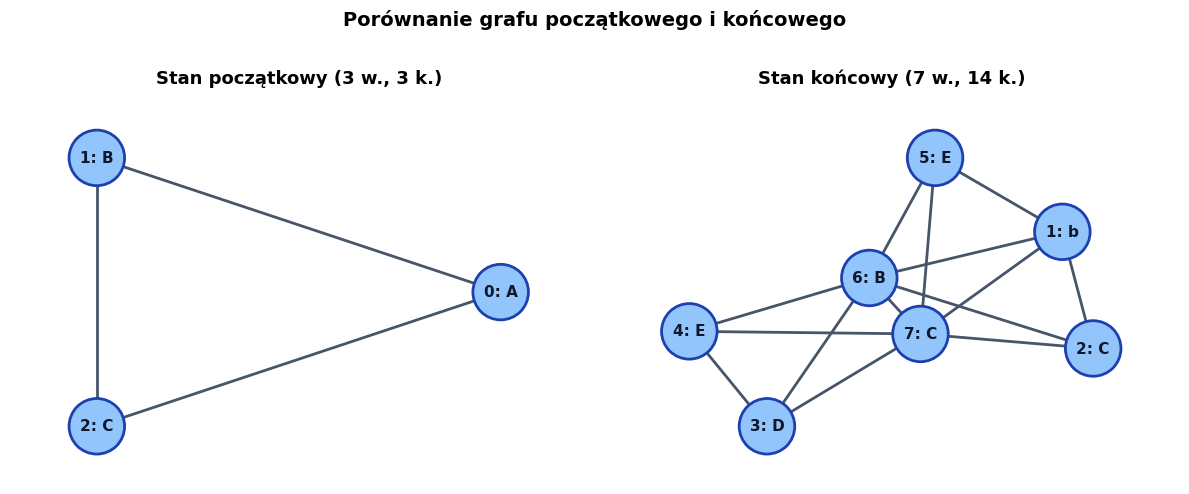

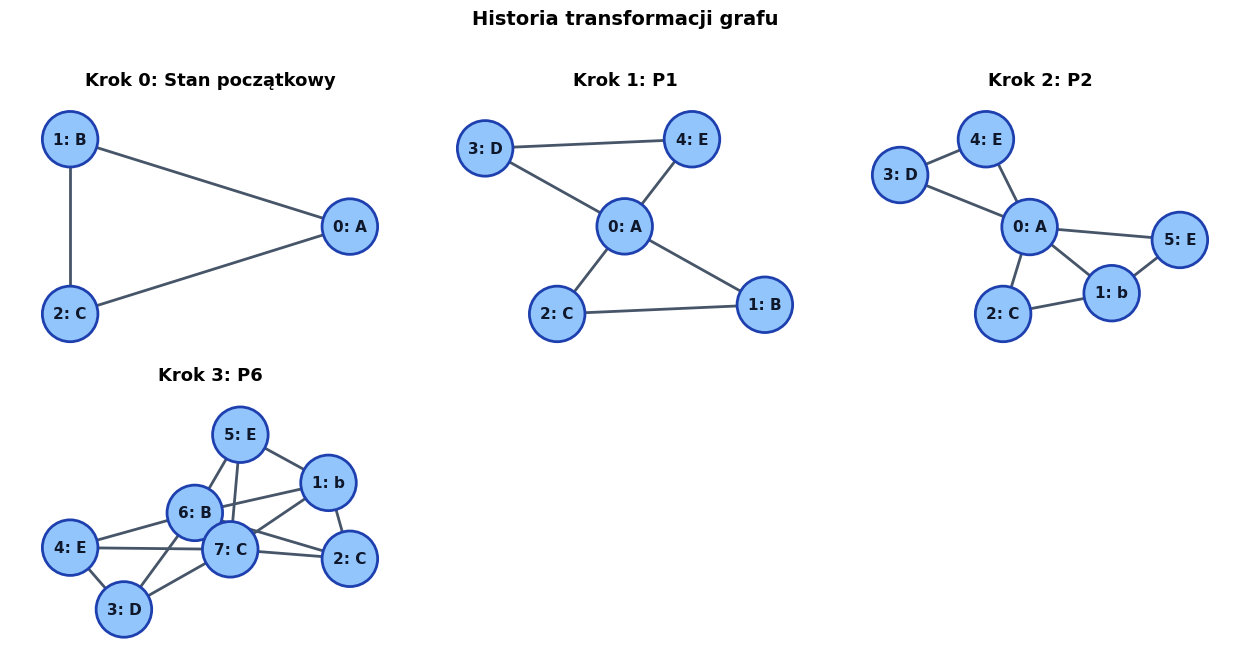

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,4,"1 (B), 2 (C), 3 (D), 4 (E)"
1,B,2,"0 (A), 2 (C)"
2,C,2,"1 (B), 0 (A)"
3,D,2,"0 (A), 4 (E)"
4,E,2,"3 (D), 0 (A)"
Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,5,"1 (b), 2 (C), 3 (D), 4 (E), 5 (E)"
1,b,3,"0 (A), 2 (C), 5 (E)"
2,C,2,"1 (b), 0 (A)"
3,D,2,"0 (A), 4 (E)"


In [15]:
wybrany_graf = gram.start_graph.copy()
domyslna_sekwencja = "P1, P6, P2, P11, P12, P13, P14, P15"
strategia_selekcji = 2
obsluga_wiszacych = 1

print("Dostępne produkcje:", ", ".join(p.name for p in gram.productions))

try:
    wpisana_sekwencja = input(f"Podaj własną kolejność produkcji (Enter = '{domyslna_sekwencja}'): ").strip()
except EOFError:
    wpisana_sekwencja = ""

sekwencja_uzytkownika = wpisana_sekwencja if wpisana_sekwencja else domyslna_sekwencja
print(f"Uruchamiam sekwencję: {sekwencja_uzytkownika}")

ts_custom = TransformationSystem(G=wybrany_graf, T=gram)
try:
    applied_custom = ts_custom.apply(
        sekwencja_uzytkownika,
        selection_strategy=strategia_selekcji,
        dangling_edges_handling=obsluga_wiszacych
    )
    print(f"Liczba wykonanych kroków: {len(applied_custom)}")
    ts_custom.visualize_initial_and_final(figsize=(12, 4.8))
    ts_custom.visualize_history(figsize_per_step=(4.2, 3.2), include_initial=True)
    ts_custom.display_history_tables(mode="connections")
except ValueError as err:
    print(f"Błąd w podanej sekwencji produkcji: {err}")
